# Learning from Job-Ad Feedback - Solution

**Business problem:** choose which of two ads to show in one featured position.

A model supports a decision; it does not make the business decision for us.

## Learning objectives

- Implement one exploration/exploitation rule against baselines.
- Interpret average simulated clicks and an individual failure.
- Explain sequential decisions and the classic RLHF pathway.

## Dataset and practical scope

Use the approved Data pipelines and ETL development excerpts. All feedback is invented: A has an 8% click probability and B 12%. These are not estimated interaction rates. No real visitor records, sequential RL model or LLM training are used.

All code is supplied. Run the cells from top to bottom.

## Libraries and settings

Use the prepared Python 3.11 Codespace kernel. No GPU or API key is needed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 7
np.random.seed(SEED)
DATA_ROOT = Path('../../../00_Data')

## 1. Inspect the two options

Labels are anonymized; quoted fragments are authentic. Clicking is not evidence of eligibility or suitability.

In [2]:
import json
panel = json.loads((DATA_ROOT / 'nlp_search_benchmark.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'ad': item['title'], 'excerpt': ' [...] '.join(item['fragments'])}
                      for item in panel['documents'][:2]]))
rates = np.array([0.08, 0.12])

,ad,excerpt
0,Data pipelines,"Entwicklung, Betrieb und Weiterentwicklung aut..."
1,ETL development,"Du bindest neue Datenquellen an, entwickelst a..."


## 2. Baselines and epsilon-greedy

Fixed A never adapts. Random ignores feedback. Epsilon-greedy initially tries both, then explores on 10% of decisions and otherwise uses the leader. The supplied simulator reveals only the chosen response.

**Coding task:** compute `clicks / displays` in the exploitation branch. Initialization makes both display counts positive.

In [3]:
def run_policy(policy, horizon=2000, seed=42, epsilon=0.1):
    if policy not in {'Fixed A', 'Random', 'Epsilon'}:
        raise ValueError('Choose Fixed A, Random or Epsilon.')
    if horizon < 2 or not 0 <= epsilon <= 1:
        raise ValueError('Use at least two visitors and epsilon between zero and one.')
    environment = np.random.default_rng(seed)
    decisions = np.random.default_rng(seed + 10000)
    potential = environment.random((horizon, 2))
    clicks = np.zeros(2, dtype=int)
    displays = np.zeros(2, dtype=int)
    cumulative = np.zeros(horizon, dtype=int)
    for visitor in range(horizon):
        if policy == 'Fixed A':
            ad = 0
        elif policy == 'Random':
            ad = int(decisions.integers(2))
        elif visitor < 2:
            ad = visitor
        elif decisions.random() < epsilon:
            ad = int(decisions.integers(2))
        else:
            estimated_rates = clicks / displays
            ad = int(decisions.choice(np.flatnonzero(estimated_rates == estimated_rates.max())))
        reward = int(potential[visitor, ad] < rates[ad])
        clicks[ad] += reward
        displays[ad] += 1
        cumulative[visitor] = clicks.sum()
    return cumulative, clicks, displays

## 3. Compare declared policies

**Coding task:** average the run matrix across runs using `axis=0`. Two hundred matched environments each contain 2,000 visitors. Policies share possible outcomes but never see an unchosen response.

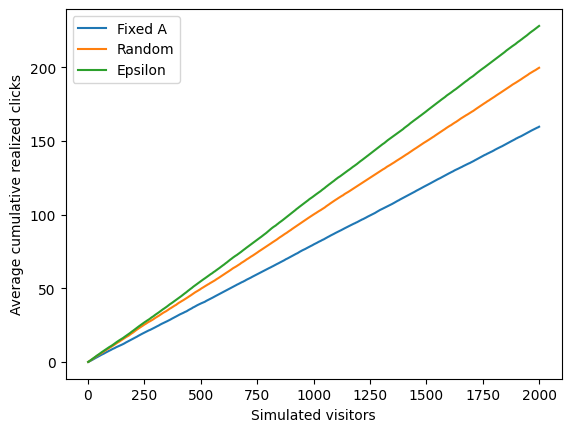

,Average final clicks
Fixed A,159.61
Random,199.60
Epsilon,227.98


In [4]:
policies = ['Fixed A', 'Random', 'Epsilon']
runs = {name: np.vstack([run_policy(name, seed=42 + i)[0] for i in range(200)])
        for name in policies}
means = {}
for name, values in runs.items():
    means[name] = values.mean(axis=0)
for name, values in means.items():
    plt.plot(np.arange(1, len(values) + 1), values, label=name)
plt.xlabel('Simulated visitors')
plt.ylabel('Average cumulative realized clicks')
plt.legend()
plt.show()
display(pd.Series({name: values[-1] for name, values in means.items()},
                  name='Average final clicks').round(2).to_frame())

### Interpret the result

Can the average gain establish better real job matches?

**Suggested answer:** No. It measures simulated clicks under invented stationary rates. Real behaviour, delayed outcomes and usefulness require new evidence.

**Self-check:** Identify the metric, simulation assumptions and a meaningful later outcome.

**Difficulty:** moderate. A common mistake is treating a model score as business value.

## 4. Inspect a deliberately selected failure

Seed 61 is the lecture's unlucky example, not a typical run or an estimate of failure frequency. Exploration can correct estimates slowly; do not hide this result.

Random | Final clicks: 206
Epsilon | Final clicks: 162


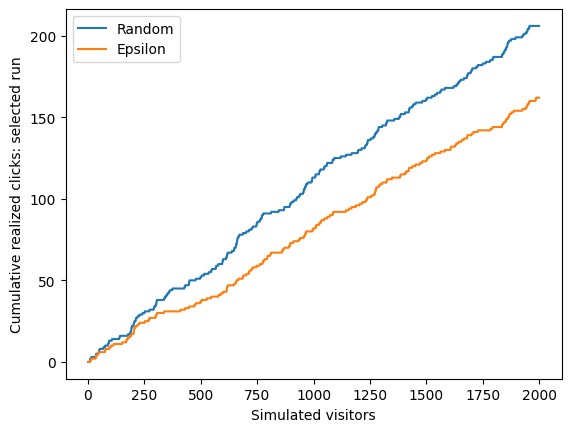

,ad,first 20 displays,first 20 clicks
0,A,18,2
1,B,2,0


In [5]:
for name in ['Random', 'Epsilon']:
    curve, clicks, displays = run_policy(name, seed=61)
    print(name, '| Final clicks:', int(curve[-1]))
    plt.plot(np.arange(1, len(curve) + 1), curve, label=name)
plt.xlabel('Simulated visitors')
plt.ylabel('Cumulative realized clicks: selected run')
plt.legend()
plt.show()
early_curve, early_clicks, early_displays = run_policy('Epsilon', horizon=20, seed=61)
display(pd.DataFrame({'ad': ['A', 'B'], 'first 20 displays': early_displays,
                      'first 20 clicks': early_clicks}))

## 5. Sequential decisions and human feedback

**Short written activity:**
1. Explain how asking for location can change a later recommendation. Do not invent locations for A/B. Is a scripted question automatically RL-trained?
2. Sort these stages: next-token targets; examples of desired answers; supervised preference-score fitting; reward-based language-model policy updates.
3. Suggest a reward that is closer to useful matching than clicks, and a failure that the reward might still miss.

### Interpret the result

Which of those language-model stages uses reinforcement learning?

**Suggested answer:** The reward-based policy update. Text and example-answer targets are supervised/self-supervised learning; fitting a scoring model from preference comparisons is supervised. Ordinary prompting does not normally change weights. A scripted assistant is not automatically RL-trained.

**Self-check:** Distinguish targets, score fitting and policy updates; identify proxy-reward risks.

**Difficulty:** moderate. A common mistake is treating a model score as business value.

## Summary and business implications

Bandits and sequential RL can both seek accumulated reward. Sequential RL models action-dependent future situations. RLHF is not epsilon-greedy or a truth guarantee.

## Limitations

This is a small teaching example, not evidence of deployment performance. Keep evaluation separate from fitting and model selection. Check errors and the user's decision, not only a headline metric.

## Further exercises

- Optional: rerun a predeclared epsilon under a new environment seed, not to tune on this test.
- What changes if clicks arrive late or rates drift?
- Why might a planned A/B experiment be preferable for treatment-effect estimation?

## References

**Required reading:** Sutton & Barto (2018), *Reinforcement Learning: An Introduction*, second edition,
Chapter 2 opening and Sections 2.1-2.2. http://incompleteideas.net/book/the-book-2nd.html
**Instructor reference:** Ouyang et al. (2022), *Training language models to follow instructions with human feedback*.
https://arxiv.org/abs/2203.02155
Chapter 2 provides the feedback concepts, not a description of modern LLM training.

### Jupyter notebook - footer info

Include your name, submission date and a short description of your changes when submitting.